<a href="https://colab.research.google.com/github/rcoello48/AI-Stock-Market-Prediction/blob/main/Data_Collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install yfinance pandas numpy matplotlib seaborn

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [8]:
import os

PROJECT_PATH = "/content/drive/MyDrive/AI_Stock_Prediction"

folders = [
    "datasets/raw",
    "datasets/processed",
    "notebooks",
    "models",
    "results",
    "documentation"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_PATH, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [9]:
tickers = [
    "AAPL",
    "MSFT",
    "NVDA",
    "AMZN",
    "TSLA",
    "GOOGL",
    "META",
    "JPM",
    "SPY",
    "QQQ",
    "^VIX"
]

print("Number of financial instruments:", len(tickers))
print("Instruments:", tickers)

Number of financial instruments: 11
Instruments: ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'TSLA', 'GOOGL', 'META', 'JPM', 'SPY', 'QQQ', '^VIX']


In [10]:
# Install yfinance to retrieve historical financial market data
!pip install yfinance

In [11]:
# Download historical daily stock market data from Yahoo Finance

data = yf.download(
    tickers=tickers,          # List of stocks and market indicators
    start="2015-01-01",       # Beginning of historical data
    end="2026-11-01",         # End date (exclusive)
    interval="1d",            # Daily trading frequency
    auto_adjust=True,         # Adjust prices for dividends and stock splits
    group_by="ticker",        # Organise data by financial instrument
    progress=True             # Display download progress
)

# Display confirmation that the download operation has completed
print("Historical market data download completed!")

[*********************100%***********************]  11 of 11 completed


Historical market data download completed!


In [12]:
# Display the dimensions of our downloaded dataset
# The first number represents trading dates (rows)
# The second number represents data columns

print("Dataset dimensions:", data.shape)

# Display the total number of observations
print("Number of trading dates:", data.shape[0])

# Display the total number of columns
print("Number of columns:", data.shape[1])

Dataset dimensions: (2977, 55)
Number of trading dates: 2977
Number of columns: 55


In [13]:
# Display the first five rows of our dataset
# This allows us to inspect the downloaded financial information

display(data.head())

Ticker            QQQ                                                    AAPL  \
Price            Open       High        Low      Close      Volume       Open   
Date                                                                            
2015-01-02  95.215148  95.618908  94.003853  94.462677  31314600.0  24.627197   
2015-01-05  94.049769  94.159890  92.810946  93.077065  36521300.0  23.941824   
2015-01-06  93.214714  93.370713  91.416124  91.829063  66205500.0  23.554914   
2015-01-07  92.434724  93.233074  92.214484  93.012840  37577400.0  23.700833   
2015-01-08  93.802006  94.976595  93.701064  94.793068  40212600.0  24.149649   

Ticker                                                    ...       MSFT  \
Price            High        Low      Close       Volume  ...       Open   
Date                                                      ...              
2015-01-02  24.638253  23.733994  24.171753  212818400.0  ...  39.522484   
2015-01-05  24.021417  23.305086  23.490801  257142000.0  ...  39.276837   
2015-01-06  23.751684  23.132632  23.493010  263188400.0  ...  39.285305   
2015-01-07  23.921923  23.590288  23.822433  160423600.0  ...  38.946491   
2015-01-08  24.795231  24.032470  24.737747  237458000.0  ...  39.598709   

Ticker                                                      AMZN           \
Price            High        Low      Close      Volume     Open     High   
Date                                                                        
2015-01-02  40.166226  39.420841  39.607185  27913900.0  15.6290  15.7375   
2015-01-05  39.581769  39.175194  39.242958  39673900.0  15.3505  15.4190   
2015-01-06  39.598706  38.573799  38.666973  36447900.0  15.1120  15.1500   
2015-01-07  39.353066  38.531448  39.158249  29114100.0  14.8750  15.0640   
2015-01-08  40.445740  39.573299  40.310215  29645200.0  15.0160  15.1570   

Ticker                                    
Price           Low    Close      Volume  
Date                                      
2015-01-02  15.3480  15.4260  55664000.0  
2015-01-05  15.0425  15.1095  55484000.0  
2015-01-06  14.6190  14.7645  70380000.0  
2015-01-07  14.7665  14.9210  52806000.0  
2015-01-08  14.8055  15.0230  61768000.0  

[5 rows x 55 columns]

In [16]:
# Display information about our dataset
# This shows the column names, data types and non-null observations

data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2977 entries, 2015-01-02 to 2026-10-30
Data columns (total 55 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (QQQ, Open)      2975 non-null   float64
 1   (QQQ, High)      2975 non-null   float64
 2   (QQQ, Low)       2975 non-null   float64
 3   (QQQ, Close)     2975 non-null   float64
 4   (QQQ, Volume)    2975 non-null   float64
 5   (AAPL, Open)     2975 non-null   float64
 6   (AAPL, High)     2975 non-null   float64
 7   (AAPL, Low)      2975 non-null   float64
 8   (AAPL, Close)    2975 non-null   float64
 9   (AAPL, Volume)   2975 non-null   float64
 10  (GOOGL, Open)    2975 non-null   float64
 11  (GOOGL, High)    2975 non-null   float64
 12  (GOOGL, Low)     2975 non-null   float64
 13  (GOOGL, Close)   2975 non-null   float64
 14  (GOOGL, Volume)  2975 non-null   float64
 15  (SPY, Open)      2975 non-null   float64
 16  (SPY, High)      2975 non-null   float64
 

In [17]:
# Count missing values in every column of the dataset
missing_values = data.isnull().sum()

# Display only columns that contain missing values
print("Columns containing missing values:")

display(missing_values[missing_values > 0])

# Calculate the total number of missing values
print("Total missing values:", missing_values.sum())

Columns containing missing values:


Ticker  Price 
QQQ     Open      2
        High      2
        Low       2
        Close     2
        Volume    2
AAPL    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
GOOGL   Open      2
        High      2
        Low       2
        Close     2
        Volume    2
SPY     Open      2
        High      2
        Low       2
        Close     2
        Volume    2
META    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
JPM     Open      2
        High      2
        Low       2
        Close     2
        Volume    2
TSLA    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
NVDA    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
MSFT    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
AMZN    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
dtype: int64

Total missing values: 100


In [18]:
# Identify the dates containing missing observations
# any(axis=1) checks whether at least one column is missing on a given date

missing_dates = data[data.isnull().any(axis=1)]

# Display the dates and corresponding missing observations
print("Dates containing missing values:")

display(missing_dates)

# Display the total number of affected dates
print("Number of affected dates:", len(missing_dates))

Dates containing missing values:


Ticker      QQQ                       AAPL                        ... MSFT  \
Price      Open High Low Close Volume Open High Low Close Volume  ... Open   
Date                                                              ...        
2026-05-25  NaN  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  ...  NaN   
2026-09-07  NaN  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  ...  NaN   

Ticker                           AMZN                        
Price      High Low Close Volume Open High Low Close Volume  
Date                                                         
2026-05-25  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  
2026-09-07  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  

[2 rows x 55 columns]

Number of affected dates: 2


In [19]:
# Remove rows where all financial instruments have missing values
# These dates correspond to US market holidays

data = data.dropna(how="all")

# Display the updated dataset dimensions
print("Dataset dimensions after removing empty dates:", data.shape)

# Verify that no completely empty rows remain
print("Completely empty rows:", data.isnull().all(axis=1).sum())

Dataset dimensions after removing empty dates: (2977, 55)
Completely empty rows: 0


In [20]:
# Exclude VIX because it has observations on the dates
# when the regular US stock market was closed

stock_data = data.loc[
    :,
    data.columns.get_level_values(0) != "^VIX"
]

# Identify dates where all stock and ETF observations are missing
market_closed_dates = stock_data.isna().all(axis=1)

# Display the dates identified as market closures
print("Potential US market closure dates:")

display(data.loc[market_closed_dates])

# Count the identified dates
print("Number of identified dates:", market_closed_dates.sum())

Potential US market closure dates:


Ticker      QQQ                       AAPL                        ... MSFT  \
Price      Open High Low Close Volume Open High Low Close Volume  ... Open   
Date                                                              ...        
2026-05-25  NaN  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  ...  NaN   
2026-09-07  NaN  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  ...  NaN   

Ticker                           AMZN                        
Price      High Low Close Volume Open High Low Close Volume  
Date                                                         
2026-05-25  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  
2026-09-07  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  

[2 rows x 55 columns]

Number of identified dates: 2


In [21]:
# Remove dates when all stock and ETF markets were closed
# Keep all valid trading observations

data = data.loc[~market_closed_dates].copy()

# Display the updated dataset dimensions
print("Updated dataset dimensions:", data.shape)

# Verify that the identified market closure dates were removed
print("Remaining market closure dates:",
      data.loc[market_closed_dates.reindex(data.index, fill_value=False)].shape[0]
)

Updated dataset dimensions: (2975, 55)
Remaining market closure dates: 0


In [22]:
# Count missing values across all columns
remaining_missing = data.isnull().sum()

# Display columns that still contain missing values
print("Remaining missing values by column:")

display(remaining_missing[remaining_missing > 0])

# Calculate the total number of missing values
print("Total remaining missing values:", remaining_missing.sum())

Remaining missing values by column:


,,0
Ticker,Price,


Total remaining missing values: 0


In [23]:
# Define the destination path for our processed dataset
processed_path = f"{PROJECT_PATH}/datasets/processed/cleaned_stock_market_data.csv"

# Save the cleaned financial dataset as a CSV file
# index=True preserves the trading dates
# header=True preserves our ticker and price column levels
data.to_csv(processed_path, index=True, header=True)

# Display a confirmation message
print("Cleaned dataset saved successfully!")

# Display the location of the saved dataset
print("Saved file:", processed_path)

Cleaned dataset saved successfully!
Saved file: /content/drive/MyDrive/AI_Stock_Prediction/datasets/processed/cleaned_stock_market_data.csv


In [24]:
# Load the cleaned financial dataset from Google Drive
# This allows us to reuse the saved dataset without downloading it again

cleaned_data = pd.read_csv(
    processed_path,
    header=[0, 1],       # Read both levels of our MultiIndex columns
    index_col=0,         # Use the Date column as the DataFrame index
    parse_dates=True     # Convert the index into datetime format
)

# Display the dataset dimensions
print("Dataset dimensions:", cleaned_data.shape)

# Display the first five observations
display(cleaned_data.head())

Dataset dimensions: (2975, 55)


Ticker            QQQ                                                    AAPL  \
Price            Open       High        Low      Close      Volume       Open   
Date                                                                            
2015-01-02  95.215148  95.618908  94.003853  94.462677  31314600.0  24.627197   
2015-01-05  94.049769  94.159890  92.810946  93.077065  36521300.0  23.941824   
2015-01-06  93.214714  93.370713  91.416124  91.829063  66205500.0  23.554914   
2015-01-07  92.434724  93.233074  92.214484  93.012840  37577400.0  23.700833   
2015-01-08  93.802006  94.976595  93.701064  94.793068  40212600.0  24.149649   

Ticker                                                    ...       MSFT  \
Price            High        Low      Close       Volume  ...       Open   
Date                                                      ...              
2015-01-02  24.638253  23.733994  24.171753  212818400.0  ...  39.522484   
2015-01-05  24.021417  23.305086  23.490801  257142000.0  ...  39.276837   
2015-01-06  23.751684  23.132632  23.493010  263188400.0  ...  39.285305   
2015-01-07  23.921923  23.590288  23.822433  160423600.0  ...  38.946491   
2015-01-08  24.795231  24.032470  24.737747  237458000.0  ...  39.598709   

Ticker                                                      AMZN           \
Price            High        Low      Close      Volume     Open     High   
Date                                                                        
2015-01-02  40.166226  39.420841  39.607185  27913900.0  15.6290  15.7375   
2015-01-05  39.581769  39.175194  39.242958  39673900.0  15.3505  15.4190   
2015-01-06  39.598706  38.573799  38.666973  36447900.0  15.1120  15.1500   
2015-01-07  39.353066  38.531448  39.158249  29114100.0  14.8750  15.0640   
2015-01-08  40.445740  39.573299  40.310215  29645200.0  15.0160  15.1570   

Ticker                                    
Price           Low    Close      Volume  
Date                                      
2015-01-02  15.3480  15.4260  55664000.0  
2015-01-05  15.0425  15.1095  55484000.0  
2015-01-06  14.6190  14.7645  70380000.0  
2015-01-07  14.7665  14.9210  52806000.0  
2015-01-08  14.8055  15.0230  61768000.0  

[5 rows x 55 columns]

In [25]:
# Check that the dataset dates were loaded as datetime values
print("Date index type:", type(cleaned_data.index))

# Display all available ticker symbols
print("\nAvailable tickers:")
print(cleaned_data.columns.get_level_values(0).unique().tolist())

# Display all available price fields
print("\nAvailable price fields:")
print(cleaned_data.columns.get_level_values(1).unique().tolist())

# Confirm the date range covered by our dataset
print("\nDataset start date:", cleaned_data.index.min())
print("Dataset end date:", cleaned_data.index.max())

Date index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

Available tickers:
['QQQ', 'AAPL', 'GOOGL', 'SPY', 'META', 'JPM', '^VIX', 'TSLA', 'NVDA', 'MSFT', 'AMZN']

Available price fields:
['Open', 'High', 'Low', 'Close', 'Volume']

Dataset start date: 2015-01-02 00:00:00
Dataset end date: 2026-10-30 00:00:00


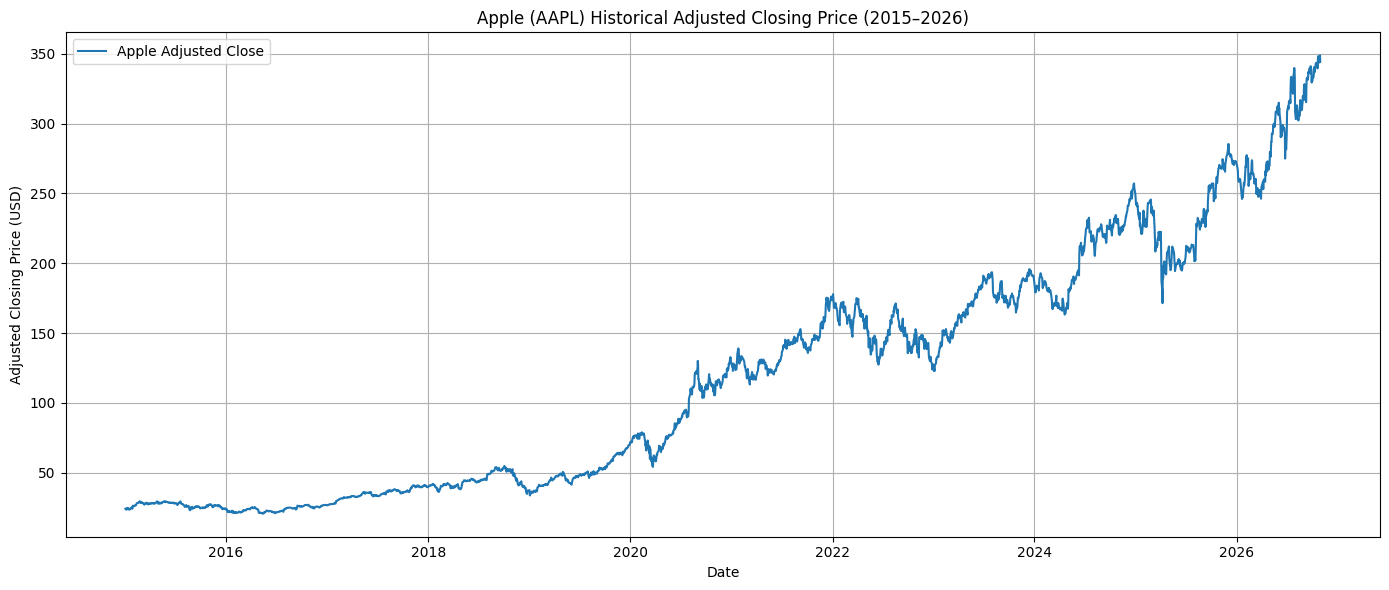

In [26]:
# Create a figure for Apple's historical adjusted closing price
plt.figure(figsize=(14, 6))

# Extract Apple's adjusted closing prices and plot them over time
plt.plot(
    cleaned_data.index,
    cleaned_data[("AAPL", "Close")],
    label="Apple Adjusted Close"
)

# Add a descriptive title and axis labels
plt.title("Apple (AAPL) Historical Adjusted Closing Price (2015–2026)")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")

# Display a grid and legend to make the chart easier to read
plt.grid(True)
plt.legend()

# Improve spacing and display the chart
plt.tight_layout()
plt.show()

Apple Daily Returns Summary:


,AAPL
,Close
count,2974.000000
mean,0.001056
std,0.018037
min,-0.128647
25%,-0.007328
50%,0.001001
75%,0.010016
max,0.153289


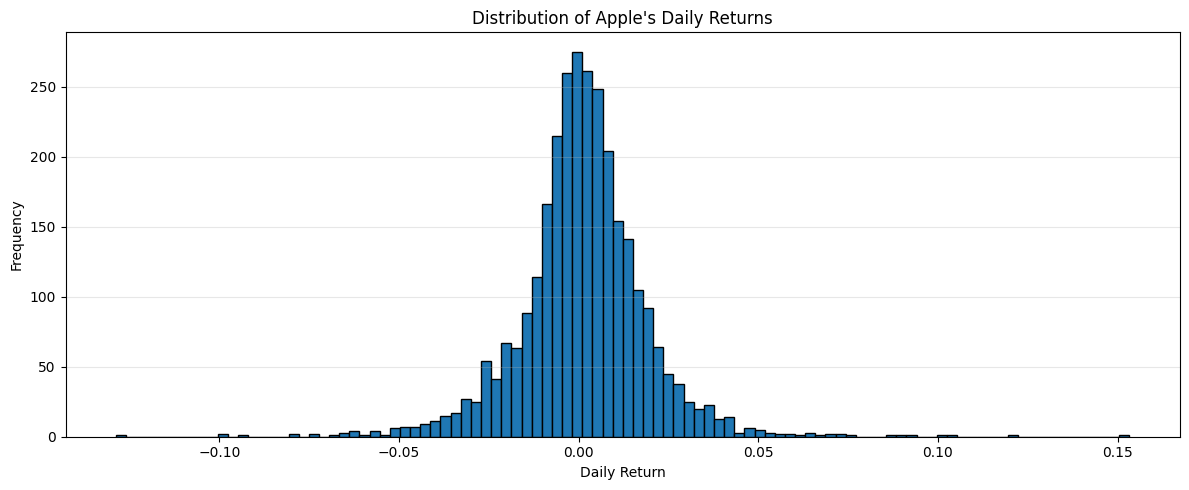

In [27]:
# Calculate Apple's daily percentage returns
# pct_change() measures the percentage change from the previous trading day
aapl_returns = cleaned_data[("AAPL", "Close")].pct_change()

# Remove the first missing value because it has no previous trading day
aapl_returns = aapl_returns.dropna()

# Display basic statistics about Apple's daily returns
print("Apple Daily Returns Summary:")
display(aapl_returns.describe())

# Plot the distribution of daily returns
plt.figure(figsize=(12, 5))

plt.hist(
    aapl_returns,
    bins=100,
    edgecolor="black"
)

# Add chart labels and title
plt.title("Distribution of Apple's Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")

# Display the chart
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


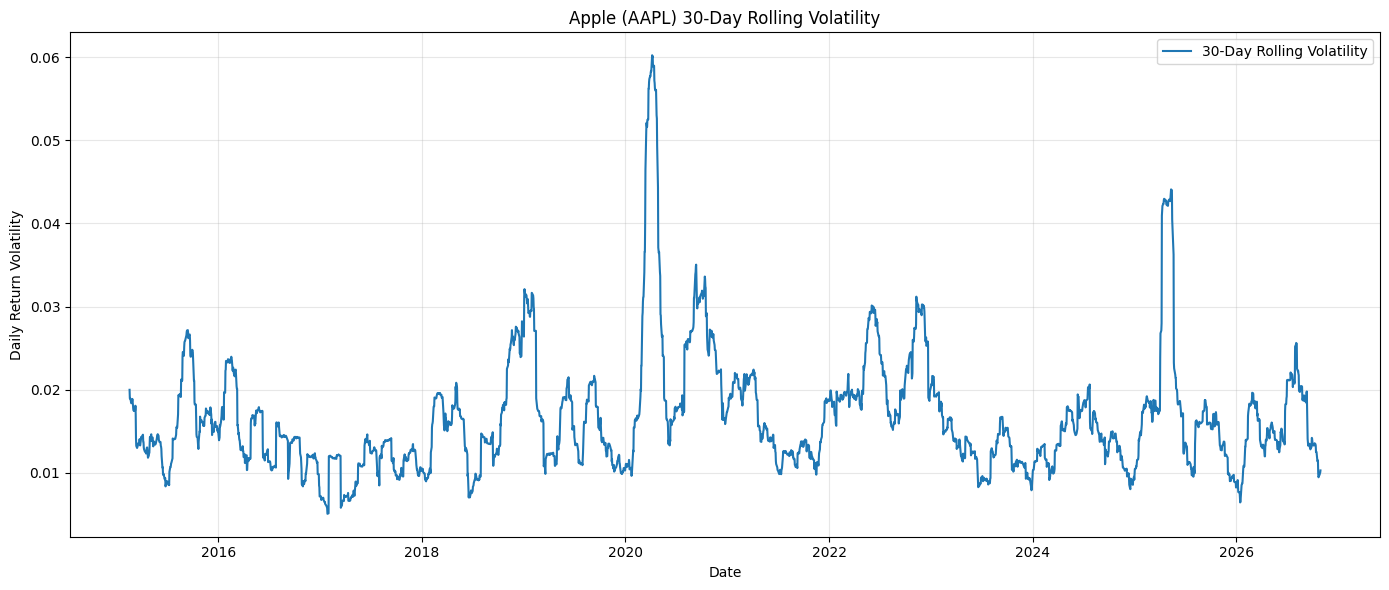

Average 30-day rolling volatility: 1.6579 %


In [28]:
# Calculate rolling 30-day volatility using Apple's daily returns
# A 30-day window represents the previous 30 trading observations
aapl_volatility = aapl_returns.rolling(window=30).std()

# Create a figure for the rolling volatility chart
plt.figure(figsize=(14, 6))

# Plot the rolling volatility over time
plt.plot(
    aapl_volatility.index,
    aapl_volatility,
    label="30-Day Rolling Volatility"
)

# Add chart title and axis labels
plt.title("Apple (AAPL) 30-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Daily Return Volatility")

# Add a legend and grid
plt.legend()
plt.grid(True, alpha=0.3)

# Display the chart
plt.tight_layout()
plt.show()

# Display the average 30-day rolling volatility
print(
    "Average 30-day rolling volatility:",
    round(aapl_volatility.mean() * 100, 4),
    "%"
)

In [29]:
# Display the average rolling volatility as a percentage
print(
    "Average 30-day rolling volatility:",
    round(aapl_volatility.mean() * 100, 4),
    "%"
)

Average 30-day rolling volatility: 1.6579 %


,Average Daily Return (%),Daily Volatility (%),Minimum Daily Return (%),Maximum Daily Return (%)
Ticker,,,,
QQQ,0.076,1.380,-11.979,12.003
AAPL,0.106,1.804,-12.865,15.329
GOOGL,0.097,1.843,-12.641,16.258
SPY,0.056,1.102,-10.942,10.502
META,0.098,2.394,-26.390,23.282
JPM,0.081,1.689,-14.965,18.012
TSLA,0.175,3.588,-21.063,22.690
NVDA,0.249,3.024,-18.756,29.807
MSFT,0.102,1.734,-14.739,15.507


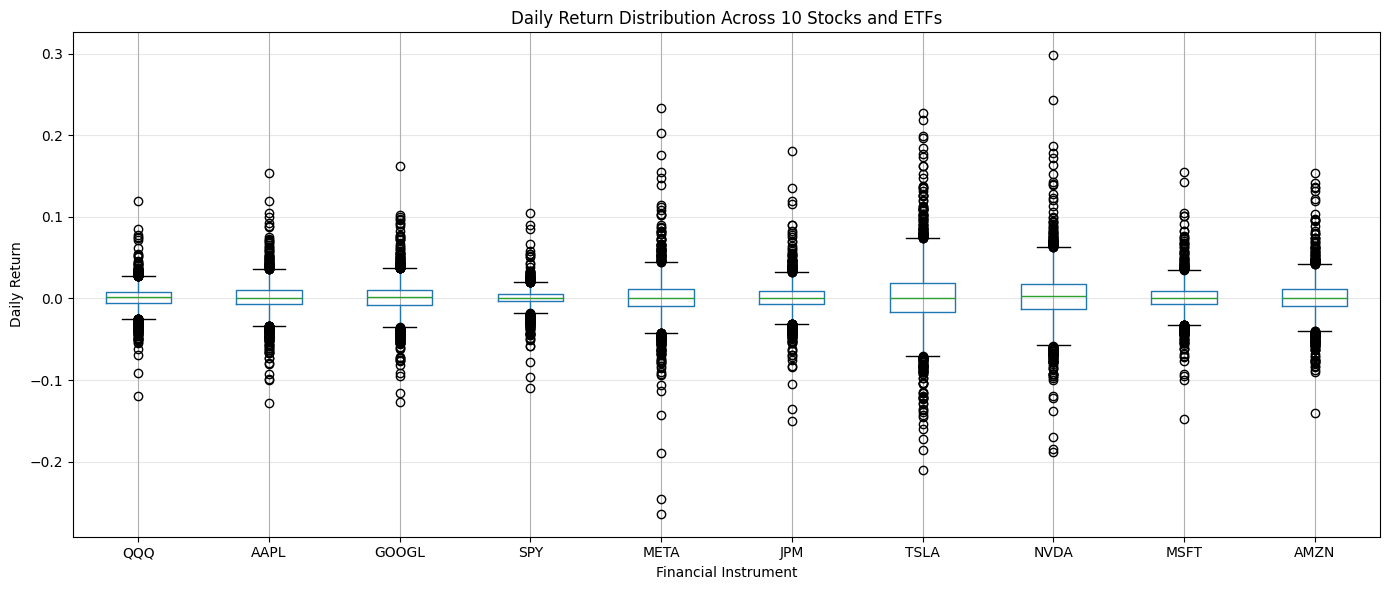

In [30]:
# Extract the adjusted closing prices for all financial instruments
close_prices = cleaned_data.xs("Close", axis=1, level=1)

# Exclude VIX because it is a volatility index, not a stock or ETF
equity_prices = close_prices.drop(columns=["^VIX"])

# Calculate daily percentage returns for all 10 stocks and ETFs
asset_returns = equity_prices.pct_change().dropna()

# Calculate summary statistics for each asset
# Standard deviation measures the historical variability of daily returns
return_summary = pd.DataFrame({
    "Average Daily Return (%)": asset_returns.mean() * 100,
    "Daily Volatility (%)": asset_returns.std() * 100,
    "Minimum Daily Return (%)": asset_returns.min() * 100,
    "Maximum Daily Return (%)": asset_returns.max() * 100
})

# Display the comparison table
display(return_summary.round(3))

# Create a boxplot to compare the distribution of daily returns
plt.figure(figsize=(14, 6))

asset_returns.boxplot()

# Add chart labels and title
plt.title("Daily Return Distribution Across 10 Stocks and ETFs")
plt.xlabel("Financial Instrument")
plt.ylabel("Daily Return")

# Display the chart
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Ticker,QQQ,AAPL,GOOGL,SPY,META,JPM,TSLA,NVDA,MSFT,AMZN
Ticker,,,,,,,,,,
QQQ,1.00,0.76,0.75,0.93,0.68,0.53,0.56,0.73,0.80,0.73
AAPL,0.76,1.00,0.55,0.73,0.49,0.41,0.42,0.50,0.62,0.52
GOOGL,0.75,0.55,1.00,0.69,0.58,0.38,0.38,0.50,0.63,0.63
SPY,0.93,0.73,0.69,1.00,0.60,0.71,0.50,0.65,0.75,0.63
META,0.68,0.49,0.58,0.60,1.00,0.32,0.34,0.47,0.54,0.58
JPM,0.53,0.41,0.38,0.71,0.32,1.00,0.28,0.33,0.41,0.30
TSLA,0.56,0.42,0.38,0.50,0.34,0.28,1.00,0.41,0.39,0.40
NVDA,0.73,0.50,0.50,0.65,0.47,0.33,0.41,1.00,0.57,0.50
MSFT,0.80,0.62,0.63,0.75,0.54,0.41,0.39,0.57,1.00,0.63


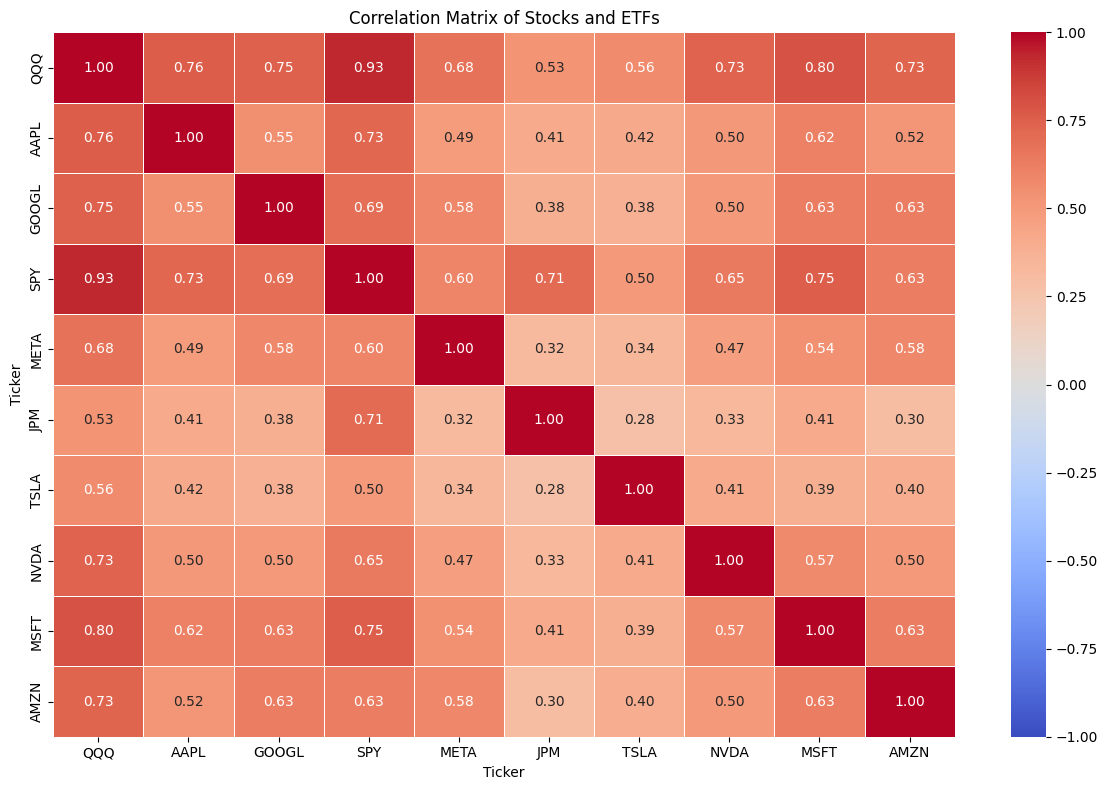

In [31]:
# Calculate the correlation matrix using daily returns
# Correlation helps identify assets that move together
correlation_matrix = asset_returns.corr()

# Display the numerical correlation matrix
display(correlation_matrix.round(2))

# Create a heatmap to visualise relationships between assets
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,          # Display correlation values inside each cell
    cmap="coolwarm",     # Use colours to distinguish positive and negative relationships
    fmt=".2f",           # Display values to two decimal places
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

# Add a title
plt.title("Correlation Matrix of Stocks and ETFs")

# Improve spacing and display the chart
plt.tight_layout()
plt.show()

Correlation Between Asset Returns and Daily VIX Changes:


,VIX Change
SPY,-0.730
QQQ,-0.697
MSFT,-0.544
GOOGL,-0.519
AAPL,-0.518
JPM,-0.514
NVDA,-0.498
AMZN,-0.485
META,-0.435
TSLA,-0.376


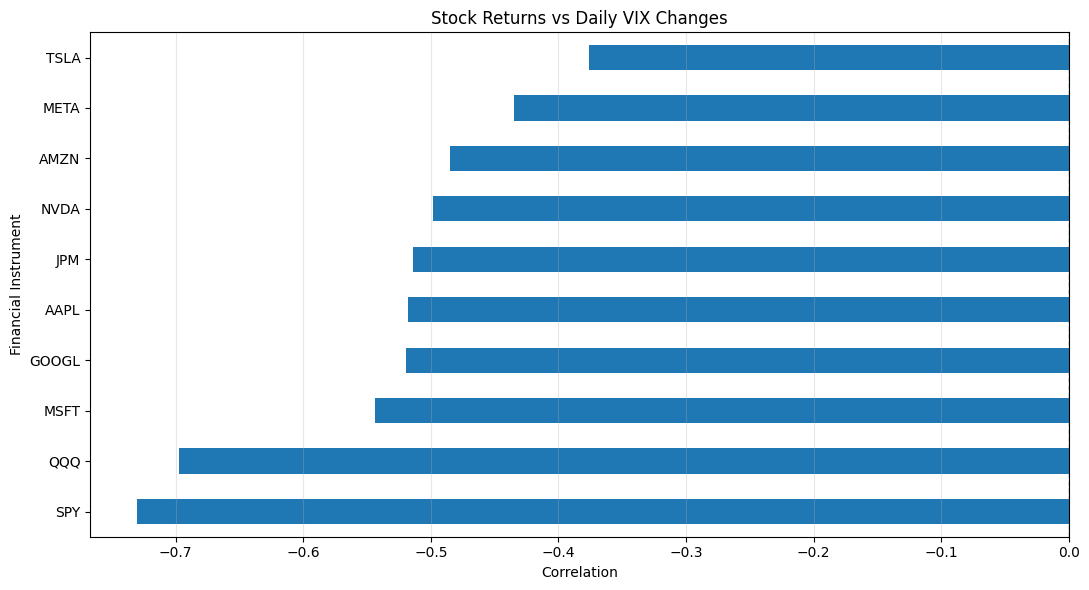

In [32]:
# Extract the VIX adjusted closing price
vix_prices = cleaned_data[("^VIX", "Close")]

# Calculate daily percentage changes in VIX
# This measures how much the VIX rises or falls each trading day
vix_returns = vix_prices.pct_change()

# Combine stock returns and VIX changes into one DataFrame
# Aligning by date ensures that observations correspond to the same trading day
vix_comparison = asset_returns.join(
    vix_returns.rename("VIX Change")
).dropna()

# Calculate the correlation between each asset's return and VIX changes
vix_correlation = (
    vix_comparison.corr()["VIX Change"]
    .drop("VIX Change")
    .sort_values()
)

# Display the correlations
print("Correlation Between Asset Returns and Daily VIX Changes:")
display(vix_correlation.round(3))

# Visualise the relationships using a horizontal bar chart
plt.figure(figsize=(11, 6))

vix_correlation.plot(kind="barh")

# Add chart labels and title
plt.title("Stock Returns vs Daily VIX Changes")
plt.xlabel("Correlation")
plt.ylabel("Financial Instrument")

# Add a reference line at zero correlation
plt.axvline(x=0, linestyle="--", linewidth=1)

# Display the chart
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Create an empty DataFrame to store machine-learning features
# Each row represents one trading date
features = pd.DataFrame(index=cleaned_data.index)

# Identify the 10 stocks and ETFs
# VIX will be handled separately as a market indicator
asset_tickers = equity_prices.columns.tolist()

# Generate technical indicators for every stock and ETF
for ticker in asset_tickers:

    # Extract the adjusted closing price for the current asset
    price = cleaned_data[(ticker, "Close")]

    # Calculate daily percentage return
    features[f"{ticker}_return_1d"] = price.pct_change()

    # Calculate returns over the previous 5 trading days
    features[f"{ticker}_return_5d"] = price.pct_change(periods=5)

    # Calculate returns over the previous 20 trading days
    features[f"{ticker}_return_20d"] = price.pct_change(periods=20)

    # Calculate the 5-day moving average relative to the current price
    features[f"{ticker}_sma_5_ratio"] = (
        price / price.rolling(window=5).mean() - 1
    )

    # Calculate the 20-day moving average relative to the current price
    features[f"{ticker}_sma_20_ratio"] = (
        price / price.rolling(window=20).mean() - 1
    )

    # Calculate 20-day rolling volatility using daily returns
    features[f"{ticker}_volatility_20d"] = (
        price.pct_change().rolling(window=20).std()
    )

# Add VIX market information as additional model features
vix_price = cleaned_data[("^VIX", "Close")]

# Current VIX level
features["VIX_level"] = vix_price

# Daily percentage change in VIX
features["VIX_change_1d"] = vix_price.pct_change()

# Five-day percentage change in VIX
features["VIX_change_5d"] = vix_price.pct_change(periods=5)

# Display the dimensions of the newly created feature dataset
print("Feature dataset dimensions:", features.shape)

# Display the first five rows
display(features.head())

Feature dataset dimensions: (2975, 63)


,QQQ_return_1d,QQQ_return_5d,QQQ_return_20d,QQQ_sma_5_ratio,QQQ_sma_20_ratio,QQQ_volatility_20d,AAPL_return_1d,AAPL_return_5d,AAPL_return_20d,AAPL_sma_5_ratio,...,MSFT_volatility_20d,AMZN_return_1d,AMZN_return_5d,AMZN_return_20d,AMZN_sma_5_ratio,AMZN_sma_20_ratio,AMZN_volatility_20d,VIX_level,VIX_change_1d,VIX_change_5d
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.790001,NaN,NaN
2015-01-05,-0.014668,NaN,NaN,NaN,NaN,NaN,-0.028171,NaN,NaN,NaN,...,NaN,-0.020517,NaN,NaN,NaN,NaN,NaN,19.920000,0.119730,NaN
2015-01-06,-0.013408,NaN,NaN,NaN,NaN,NaN,0.000094,NaN,NaN,NaN,...,NaN,-0.022833,NaN,NaN,NaN,NaN,NaN,21.120001,0.060241,NaN
2015-01-07,0.012891,NaN,NaN,NaN,NaN,NaN,0.014022,NaN,NaN,NaN,...,NaN,0.010600,NaN,NaN,NaN,NaN,NaN,19.309999,-0.085701,NaN
2015-01-08,0.019140,NaN,NaN,0.014536,NaN,NaN,0.038422,NaN,NaN,0.033187,...,NaN,0.006836,NaN,NaN,-0.001714,NaN,NaN,17.010000,-0.119109,NaN


In [34]:
# Count missing values in every engineered feature
missing_features = features.isnull().sum()

# Display only features containing missing values
display(
    missing_features[missing_features > 0]
    .sort_values(ascending=False)
)

# Calculate the total number of missing feature values
print("\nTotal missing feature values:", features.isnull().sum().sum())

# Identify how many dates contain at least one missing feature
print(
    "Rows containing missing values:",
    features.isnull().any(axis=1).sum()
)

# Identify the first date where all features are available
print(
    "First complete feature date:",
    features.dropna().index.min()
)

,0
QQQ_volatility_20d,20
QQQ_return_20d,20
AAPL_volatility_20d,20
AAPL_return_20d,20
GOOGL_volatility_20d,20
...,...
TSLA_return_1d,1
NVDA_return_1d,1
MSFT_return_1d,1
AMZN_return_1d,1



Total missing feature values: 696
Rows containing missing values: 20
First complete feature date: 2015-02-02 00:00:00


In [35]:
# Remove rows containing missing feature values
# The first 20 observations are incomplete because of rolling calculations
features_clean = features.dropna().copy()

# Display the dimensions after cleaning
print("Original feature dimensions:", features.shape)
print("Cleaned feature dimensions:", features_clean.shape)

# Verify that no missing values remain
print(
    "\nRemaining missing values:",
    features_clean.isnull().sum().sum()
)

# Display the first available date
print("First available date:", features_clean.index.min())

# Display the final available date
print("Last available date:", features_clean.index.max())

Original feature dimensions: (2975, 63)
Cleaned feature dimensions: (2955, 63)

Remaining missing values: 0
First available date: 2015-02-02 00:00:00
Last available date: 2026-10-30 00:00:00


In [36]:
# Create an empty DataFrame to store our prediction targets
targets = pd.DataFrame(index=features_clean.index)

# Loop through all 10 stocks and ETFs
for ticker in asset_tickers:

    # Extract the current adjusted closing price
    current_price = close_prices[ticker]

    # Shift prices by one trading day to obtain the NEXT trading day's price
    next_price = current_price.shift(-1)

    # Classification target:
    # 1 means the next day's price is higher than today's price
    # 0 means the next day's price is equal to or lower than today's price
    targets[f"{ticker}_direction"] = (
        next_price > current_price
    ).astype(int)

    # Regression target:
    # Predict the next trading day's adjusted closing price
    targets[f"{ticker}_next_close"] = next_price

# Remove the final observation because its next trading day's price is unknown
# This prevents us from creating an invalid prediction target
targets = targets.iloc[:-1].copy()

# Align the feature dataset with the target dataset
features_final = features_clean.loc[targets.index].copy()

# Display the dimensions of both datasets
print("Final feature dimensions:", features_final.shape)
print("Prediction target dimensions:", targets.shape)

# Display the first five prediction target observations
display(targets.head())

Final feature dimensions: (2954, 63)
Prediction target dimensions: (2954, 20)


,QQQ_direction,QQQ_next_close,AAPL_direction,AAPL_next_close,GOOGL_direction,GOOGL_next_close,SPY_direction,SPY_next_close,META_direction,META_next_close,JPM_direction,JPM_next_close,TSLA_direction,TSLA_next_close,NVDA_direction,NVDA_next_close,MSFT_direction,MSFT_next_close,AMZN_direction,AMZN_next_close
Date,,,,,,,,,,,,,,,,,,,,
2015-02-02,1,94.481049,1,26.232321,1,26.413658,1,168.781342,1,74.684685,1,41.605656,1,14.557333,1,0.481405,1,35.236496,0,18.177500
2015-02-03,0,94.398483,1,26.433506,0,26.057051,0,168.138672,1,74.912506,0,41.356247,1,14.570000,1,0.482602,1,35.439781,1,18.237499
2015-02-04,1,95.215210,1,26.622169,1,26.241791,1,169.836029,0,74.892700,1,41.642345,1,14.732667,1,0.490502,1,35.956474,1,18.694500
2015-02-05,0,94.637054,0,26.397993,1,26.442379,0,169.366440,0,73.763519,1,42.463875,0,14.490667,0,0.488347,0,35.922585,1,18.714001
2015-02-06,0,94.334236,1,26.573343,0,26.214550,0,168.608353,0,73.733818,0,42.412537,1,14.498667,0,0.487868,0,35.880253,0,18.528000


In [37]:
# Check for missing values in our prediction targets
print("Missing values in targets:", targets.isnull().sum().sum())

# Identify all classification target columns
direction_columns = [
    col for col in targets.columns
    if col.endswith("_direction")
]

# Calculate the percentage of UP and DOWN observations for each asset
direction_summary = pd.DataFrame({
    "UP (%)": targets[direction_columns].mean() * 100,
    "DOWN (%)": (1 - targets[direction_columns].mean()) * 100
})

# Display the classification target distribution
print("\nClassification Target Distribution:")
display(direction_summary.round(2))

# Verify the number of observations and target columns
print("\nTotal observations:", len(targets))
print("Total target columns:", targets.shape[1])
print("Total classification targets:", len(direction_columns))

Missing values in targets: 0

Classification Target Distribution:


,UP (%),DOWN (%)
QQQ_direction,55.99,44.01
AAPL_direction,53.08,46.92
GOOGL_direction,53.42,46.58
SPY_direction,54.64,45.36
META_direction,52.37,47.63
JPM_direction,52.51,47.49
TSLA_direction,51.59,48.41
NVDA_direction,54.23,45.77
MSFT_direction,53.32,46.68
AMZN_direction,53.08,46.92



Total observations: 2954
Total target columns: 20
Total classification targets: 10


In [38]:
# Define file paths for saving the engineered datasets
features_path = f"{PROJECT_PATH}/datasets/processed/features.csv"
targets_path = f"{PROJECT_PATH}/datasets/processed/targets.csv"

# Save the cleaned machine-learning features
features_final.to_csv(features_path, index=True)

# Save the classification and regression prediction targets
targets.to_csv(targets_path, index=True)

# Confirm that both datasets have been saved
print("Feature dataset saved successfully!")
print("Location:", features_path)

print("\nTarget dataset saved successfully!")
print("Location:", targets_path)

# Display the final dataset dimensions
print("\nFinal features:", features_final.shape)
print("Final targets:", targets.shape)

Feature dataset saved successfully!
Location: /content/drive/MyDrive/AI_Stock_Prediction/datasets/processed/features.csv

Target dataset saved successfully!
Location: /content/drive/MyDrive/AI_Stock_Prediction/datasets/processed/targets.csv

Final features: (2954, 63)
Final targets: (2954, 20)


In [39]:
# ============================================================
#  CHRONOLOGICAL TRAIN, VALIDATION AND TEST SPLIT
# ============================================================

# Calculate the total number of observations
total_rows = len(features_final)

# Define the split boundaries: 70%, 15%, 15%
train_end = int(total_rows * 0.70)
validation_end = int(total_rows * 0.85)

# Split the feature dataset without shuffling
X_train = features_final.iloc[:train_end].copy()
X_validation = features_final.iloc[train_end:validation_end].copy()
X_test = features_final.iloc[validation_end:].copy()

# Split the target dataset using identical boundaries
y_train = targets.iloc[:train_end].copy()
y_validation = targets.iloc[train_end:validation_end].copy()
y_test = targets.iloc[validation_end:].copy()

# Display the dataset dimensions
print("TRAINING FEATURES:", X_train.shape)
print("VALIDATION FEATURES:", X_validation.shape)
print("TESTING FEATURES:", X_test.shape)

print("\nTRAINING TARGETS:", y_train.shape)
print("VALIDATION TARGETS:", y_validation.shape)
print("TESTING TARGETS:", y_test.shape)

# Display the date ranges for each dataset
print("\nTRAINING PERIOD:", X_train.index.min(), "to", X_train.index.max())
print("VALIDATION PERIOD:", X_validation.index.min(), "to", X_validation.index.max())
print("TESTING PERIOD:", X_test.index.min(), "to", X_test.index.max())

TRAINING FEATURES: (2067, 63)
VALIDATION FEATURES: (443, 63)
TESTING FEATURES: (444, 63)

TRAINING TARGETS: (2067, 20)
VALIDATION TARGETS: (443, 20)
TESTING TARGETS: (444, 20)

TRAINING PERIOD: 2015-02-02 00:00:00 to 2023-04-18 00:00:00
VALIDATION PERIOD: 2023-04-19 00:00:00 to 2025-01-23 00:00:00
TESTING PERIOD: 2025-01-24 00:00:00 to 2026-10-29 00:00:00


In [40]:
# ============================================================
#  VERIFY CHRONOLOGICAL DATA SPLITTING
# ============================================================

# Check that training ends before validation begins
print(
    "Training before validation:",
    X_train.index.max() < X_validation.index.min()
)

# Check that validation ends before testing begins
print(
    "Validation before testing:",
    X_validation.index.max() < X_test.index.min()
)

# Check that feature and target dates match
print(
    "Training dates match:",
    X_train.index.equals(y_train.index)
)

print(
    "Validation dates match:",
    X_validation.index.equals(y_validation.index)
)

print(
    "Testing dates match:",
    X_test.index.equals(y_test.index)
)

# Confirm that no missing values exist in the feature datasets
print(
    "\nMissing values in training:",
    X_train.isnull().sum().sum()
)

print(
    "Missing values in validation:",
    X_validation.isnull().sum().sum()
)

print(
    "Missing values in testing:",
    X_test.isnull().sum().sum()
)

Training before validation: True
Validation before testing: True
Training dates match: True
Validation dates match: True
Testing dates match: True

Missing values in training: 0
Missing values in validation: 0
Missing values in testing: 0


In [41]:
# ============================================================
# IMPORT MACHINE-LEARNING LIBRARIES
# ============================================================

# Import Logistic Regression for stock direction classification
from sklearn.linear_model import LogisticRegression

# Import StandardScaler to standardise numerical features
from sklearn.preprocessing import StandardScaler

# Import classification evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Import tools for saving trained machine-learning models
import joblib

# Confirm that all libraries were imported successfully
print("Machine-learning libraries imported successfully!")

Machine-learning libraries imported successfully!


In [42]:
# ============================================================
#  PREPARE AAPL DATA AND SCALE FEATURES
# ============================================================

# Select Apple's next-day direction as our prediction target
y_train_aapl = y_train["AAPL_direction"]
y_validation_aapl = y_validation["AAPL_direction"]
y_test_aapl = y_test["AAPL_direction"]

# Create a feature scaler
scaler_aapl = StandardScaler()

# Fit the scaler using training data and transform training features
X_train_aapl_scaled = scaler_aapl.fit_transform(X_train)

# Transform validation and testing features using the fitted scaler
X_validation_aapl_scaled = scaler_aapl.transform(X_validation)
X_test_aapl_scaled = scaler_aapl.transform(X_test)

# Display the dimensions of the prepared datasets
print("Training features:", X_train_aapl_scaled.shape)
print("Validation features:", X_validation_aapl_scaled.shape)
print("Testing features:", X_test_aapl_scaled.shape)

# Display the target dimensions
print("\nTraining targets:", y_train_aapl.shape)
print("Validation targets:", y_validation_aapl.shape)
print("Testing targets:", y_test_aapl.shape)

# Confirm that the scaler was fitted successfully
print("\nAAPL feature scaling completed successfully!")

Training features: (2067, 63)
Validation features: (443, 63)
Testing features: (444, 63)

Training targets: (2067,)
Validation targets: (443,)
Testing targets: (444,)

AAPL feature scaling completed successfully!


In [43]:
# ============================================================
#  TRAIN AAPL LOGISTIC REGRESSION MODEL
# ============================================================

# Create the Logistic Regression classifier
# max_iter=1000 allows sufficient iterations for model convergence
# random_state=42 ensures reproducible results
logistic_model_aapl = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using historical training data
# The model learns patterns associated with UP and DOWN movements
logistic_model_aapl.fit(
    X_train_aapl_scaled,
    y_train_aapl
)

# Confirm successful model training
print("AAPL Logistic Regression model trained successfully!")

# Display the number of features learned by the model
print("Number of input features:", logistic_model_aapl.n_features_in_)

# Display the classes the model predicts
print("Prediction classes:", logistic_model_aapl.classes_)

AAPL Logistic Regression model trained successfully!
Number of input features: 63
Prediction classes: [0 1]


In [44]:
# ============================================================
# STEP 35: GENERATE AAPL VALIDATION PREDICTIONS
# ============================================================

# Predict Apple's next-day price direction
aapl_validation_predictions = logistic_model_aapl.predict(
    X_validation_aapl_scaled
)

# Calculate the probability of an UP movement
aapl_validation_probabilities = logistic_model_aapl.predict_proba(
    X_validation_aapl_scaled
)[:, 1]

# Create a comparison DataFrame
validation_results = pd.DataFrame({
    "Actual Direction": y_validation_aapl,
    "Predicted Direction": aapl_validation_predictions,
    "Probability of UP": aapl_validation_probabilities
}, index=y_validation_aapl.index)

# Display the first 10 predictions
display(validation_results.head(10))

# Display the total number of validation predictions
print(
    "\nTotal validation predictions:",
    len(aapl_validation_predictions)
)

# Confirm prediction classes
print(
    "Unique predicted classes:",
    np.unique(aapl_validation_predictions)
)

,Actual Direction,Predicted Direction,Probability of UP
Date,,,
2023-04-19,0,1,0.703049
2023-04-20,0,1,0.633050
2023-04-21,1,1,0.542758
2023-04-24,0,1,0.570907
2023-04-25,0,1,0.610051
2023-04-26,1,1,0.579464
2023-04-27,1,1,0.571820
2023-04-28,0,1,0.624311
2023-05-01,0,1,0.647262



Total validation predictions: 443
Unique predicted classes: [0 1]


In [45]:
# ============================================================
# EVALUATE AAPL LOGISTIC REGRESSION MODEL
# ============================================================

# Calculate overall prediction accuracy
accuracy = accuracy_score(
    y_validation_aapl,
    aapl_validation_predictions
)

# Calculate precision: How many predicted UP movements were correct?
precision = precision_score(
    y_validation_aapl,
    aapl_validation_predictions,
    zero_division=0
)

# Calculate recall: How many actual UP movements were identified?
recall = recall_score(
    y_validation_aapl,
    aapl_validation_predictions,
    zero_division=0
)

# Calculate F1-score: Balance between precision and recall
f1 = f1_score(
    y_validation_aapl,
    aapl_validation_predictions,
    zero_division=0
)

# Calculate ROC-AUC using predicted probabilities
roc_auc = roc_auc_score(
    y_validation_aapl,
    aapl_validation_probabilities
)

# Display the evaluation metrics
print("AAPL LOGISTIC REGRESSION - VALIDATION RESULTS")
print("=" * 50)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

# Display the confusion matrix
print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_validation_aapl,
        aapl_validation_predictions
    )
)

# Display a detailed classification report
print("\nClassification Report:")
print(
    classification_report(
        y_validation_aapl,
        aapl_validation_predictions,
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)

AAPL LOGISTIC REGRESSION - VALIDATION RESULTS
Accuracy:  0.5282
Precision: 0.5563
Recall:    0.6736
F1-score:  0.6093
ROC-AUC:   0.5098

Confusion Matrix:
[[ 71 130]
 [ 79 163]]

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.47      0.35      0.40       201
          UP       0.56      0.67      0.61       242

    accuracy                           0.53       443
   macro avg       0.51      0.51      0.51       443
weighted avg       0.52      0.53      0.52       443



In [46]:
# ============================================================
# COMPARE LOGISTIC REGRESSION WITH BASELINE
# ============================================================

# Find the most common direction in the AAPL training data
majority_class = y_train_aapl.mode()[0]

# Predict that same direction for every validation observation
baseline_predictions = np.full(
    shape=len(y_validation_aapl),
    fill_value=majority_class
)

# Calculate baseline accuracy
baseline_accuracy = accuracy_score(
    y_validation_aapl,
    baseline_predictions
)

# Display the comparison
print("AAPL VALIDATION BASELINE COMPARISON")
print("=" * 50)

print(f"Majority class: {majority_class} (0 = DOWN, 1 = UP)")
print(f"Baseline accuracy:          {baseline_accuracy:.4f}")
print(f"Logistic Regression accuracy: {accuracy:.4f}")

print("\nAccuracy improvement:")
print(f"{(accuracy - baseline_accuracy) * 100:.2f} percentage points")

AAPL VALIDATION BASELINE COMPARISON
Majority class: 1 (0 = DOWN, 1 = UP)
Baseline accuracy:          0.5463
Logistic Regression accuracy: 0.5282

Accuracy improvement:
-1.81 percentage points


In [47]:
# ============================================================
# STEP 38: TEST DIFFERENT CLASSIFICATION THRESHOLDS
# ============================================================

# Test several probability thresholds for predicting UP
thresholds = [0.40, 0.45, 0.50, 0.55, 0.60, 0.65]

print("AAPL - VALIDATION THRESHOLD COMPARISON")
print("=" * 65)
print("Threshold | Accuracy | Precision | Recall | F1-score")
print("-" * 65)

for threshold in thresholds:

    # Predict UP when its probability reaches the threshold
    threshold_predictions = (
        aapl_validation_probabilities >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    threshold_accuracy = accuracy_score(
        y_validation_aapl,
        threshold_predictions
    )

    threshold_precision = precision_score(
        y_validation_aapl,
        threshold_predictions,
        zero_division=0
    )

    threshold_recall = recall_score(
        y_validation_aapl,
        threshold_predictions,
        zero_division=0
    )

    threshold_f1 = f1_score(
        y_validation_aapl,
        threshold_predictions,
        zero_division=0
    )

    # Display results for this threshold
    print(
        f"{threshold:9.2f} | "
        f"{threshold_accuracy:8.4f} | "
        f"{threshold_precision:9.4f} | "
        f"{threshold_recall:6.4f} | "
        f"{threshold_f1:8.4f}"
    )

AAPL - VALIDATION THRESHOLD COMPARISON
Threshold | Accuracy | Precision | Recall | F1-score
-----------------------------------------------------------------
     0.40 |   0.5214 |    0.5364 | 0.9132 |   0.6758
     0.45 |   0.5169 |    0.5372 | 0.8347 |   0.6537
     0.50 |   0.5282 |    0.5563 | 0.6736 |   0.6093
     0.55 |   0.5192 |    0.5662 | 0.5124 |   0.5380
     0.60 |   0.4786 |    0.5407 | 0.3017 |   0.3873
     0.65 |   0.4740 |    0.5714 | 0.1488 |   0.2361


TOP 15 AAPL LOGISTIC REGRESSION FEATURES
            Feature  Coefficient  Absolute Importance
   QQQ_sma_20_ratio    -0.630238             0.630238
      QQQ_return_5d     0.536163             0.536163
    MSFT_return_20d    -0.403424             0.403424
    SPY_sma_5_ratio    -0.358664             0.358664
 JPM_volatility_20d     0.348204             0.348204
      SPY_return_5d    -0.333150             0.333150
     QQQ_return_20d     0.318847             0.318847
   AAPL_sma_5_ratio    -0.308008             0.308008
 GOOGL_sma_20_ratio    -0.296450             0.296450
    JPM_sma_5_ratio     0.278948             0.278948
  MSFT_sma_20_ratio     0.276635             0.276635
      JPM_return_1d    -0.256661             0.256661
          VIX_level    -0.232952             0.232952
 QQQ_volatility_20d    -0.211434             0.211434
AMZN_volatility_20d     0.190336             0.190336


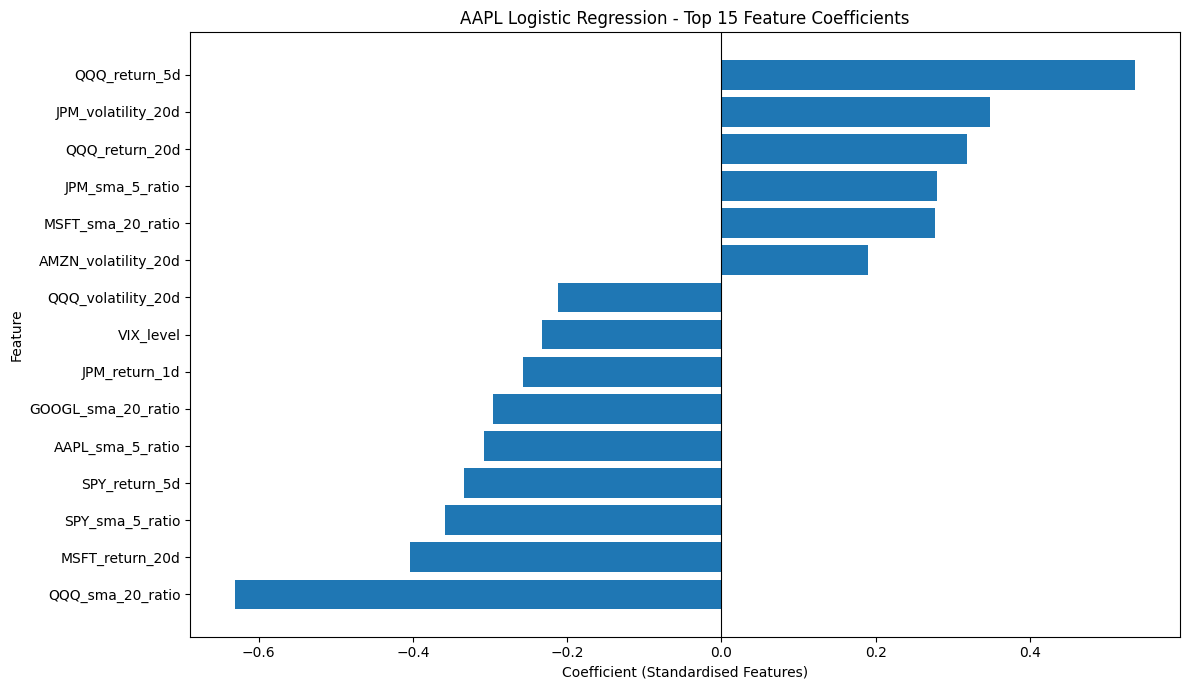

In [48]:
# ============================================================
#  AAPL LOGISTIC REGRESSION FEATURE IMPORTANCE
# ============================================================

# Extract the coefficients learned by Logistic Regression
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model_aapl.coef_[0]
})

# Calculate the absolute coefficient magnitude
feature_importance["Absolute Importance"] = (
    feature_importance["Coefficient"].abs()
)

# Sort features from most influential to least influential
feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

# Display the 15 most influential features
print("TOP 15 AAPL LOGISTIC REGRESSION FEATURES")
print("=" * 60)

print(
    feature_importance.head(15).to_string(index=False)
)

# Plot the top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.title("AAPL Logistic Regression - Top 15 Feature Coefficients")
plt.xlabel("Coefficient (Standardised Features)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [49]:
# ============================================================
# STEP 40: SAVE AAPL LOGISTIC REGRESSION MODEL
# ============================================================

# Create a folder for classification models
classification_path = os.path.join(
    PROJECT_PATH,
    "models",
    "classification"
)

os.makedirs(classification_path, exist_ok=True)

# Save the trained Logistic Regression model
joblib.dump(
    logistic_model_aapl,
    os.path.join(
        classification_path,
        "aapl_logistic_regression.pkl"
    )
)

# Save the fitted StandardScaler
joblib.dump(
    scaler_aapl,
    os.path.join(
        classification_path,
        "aapl_logistic_scaler.pkl"
    )
)

# Confirm that both files were saved
print("AAPL Logistic Regression model saved successfully!")

print("\nSaved files:")

for filename in os.listdir(classification_path):
    print(filename)

AAPL Logistic Regression model saved successfully!

Saved files:
aapl_logistic_regression.pkl
aapl_logistic_scaler.pkl
